# Growth analysis in different culture medium (C.acnes)
-   Commercial RCM;
-   RCM in house;
-   RCM without glucose;
-   RCM without glucose and starch;
-   M9;
-   M9 with glucose;


Objective: To analyze the growth of C.acnes in different culture media and determine the optimal conditions for its proliferation.

In [107]:
!pip install statannotations seaborn


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [97]:
# Change growth table
import pandas as pd

df = pd.read_csv('/home/marcos/in vitro/growth_rcmxm9C.acnes/Experiment1/growth_data.csv', sep=',', decimal=',')
output = '/home/marcos/in vitro/growth_rcmxm9C.acnes/Experiment1'

display(df)

,0h,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10
0,medium,C1,C2,C3,C4,C5,CA1,CA2,CA3,CA4,CA5
1,Commercial RCM,"0,08","0,08","0,083","0,083","0,085","0,222","0,222","0,219","0,221","0,229"
2,RCM in house,"0,095","0,104","0,097","0,095","0,099","0,204","0,196","0,274","0,252","0,3"
3,RCM without glicose,"0,11","0,071","0,076","0,075","0,077","0,209","0,19","0,196","0,148","0,133"
4,RCM without glu. And starch,"0,06","0,071","0,086","0,066","0,073","0,159","0,144","0,088","0,136","0,124"
...,...,...,...,...,...,...,...,...,...,...,...
56,RCM in house,"0,871","0,956","0,988","1,141","0,908","1,615","1,49","1,511","1,489","1,507"
57,RCM without glicose,"0,243","0,289","0,419","0,325","0,319","0,476","0,46","0,398","0,454","0,423"
58,RCM without glu. And starch,"0,228","0,192","0,083","0,182","0,275","0,358","0,383","0,402","0,414","0,399"
59,M9,"0,042","0,043","0,045","0,043","0,041","0,218","0,217","0,287","0,29","0,263"


In [98]:
# Definig the colors for each medium
colors = {
    'Commercial RCM': '#1f77b4',        # Azul
    'RCM in house': '#ff7f0e',            # Laranja
    'RCM without glicose': '#2ca02c',      # Verde
    'RCM without glu. And starch': '#d62728', # Vermelho
    'M9': '#9467bd',                   # Roxo
    'M9 with glicose': '#8c564b'        # Marrom
}
test_colors = [colors[medium] for medium in ['Commercial RCM', 'RCM in house', 'RCM without glicose', 'RCM without glu. And starch', 'M9', 'M9 with glicose']]
print(test_colors)

['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']


In [100]:
import pandas as pd

# Read without header and as text: the file has stacked blocks and decimal commas
raw = pd.read_csv("/home/marcos/in vitro/growth_rcmxm9C.acnes/Experiment1/growth_data.csv", header=None, dtype=str)

sample_cols = ["C1", "C2", "C3", "C4", "C5", "CA1", "CA2", "CA3", "CA4", "CA5", "CA6"]

records = []
current_time = None

for _, row in raw.iterrows():
    first = row.iloc[0]

    # Skip empty separator rows and the repeated header rows
    if pd.isna(first) or first == "medium":
        continue

    # Rows like "0h", "6h"... define the time of the following block
    if first.endswith("h") and first[:-1].isdigit():
        current_time = int(first[:-1])
        continue

    # Otherwise it's a medium row: one record per sample
    for sample, value in zip(sample_cols, row.iloc[1:]):
        records.append({
            "time_h": current_time,
            "medium": first,
            "sample": sample,
            "od": float(value.replace(",", ".")),  # decimal comma -> point
        })

tidy = pd.DataFrame(records)
tidy.head(12)

,time_h,medium,sample,od
0,0,Commercial RCM,C1,0.080
1,0,Commercial RCM,C2,0.080
2,0,Commercial RCM,C3,0.083
3,0,Commercial RCM,C4,0.083
4,0,Commercial RCM,C5,0.085
5,0,Commercial RCM,CA1,0.222
6,0,Commercial RCM,CA2,0.222
7,0,Commercial RCM,CA3,0.219
8,0,Commercial RCM,CA4,0.221
9,0,Commercial RCM,CA5,0.229


## 

In [101]:
import numpy as np

# Label each sample: "CA" = culture (medium + bacteria), "C" = blank (medium only)
tidy["type"] = np.where(tidy["sample"].str.startswith("CA"), "CA", "C")

# Mean OD of the blanks (C1-C5) for each medium and time point
blanks = (
    tidy[tidy["type"] == "C"]
    .groupby(["time_h", "medium"])["od"]
    .mean()
    .rename("blank_mean")
    .reset_index()
)

# Attach the blank mean to every CA row, then subtract
cultures = tidy[tidy["type"] == "CA"].merge(blanks, on=["time_h", "medium"])
cultures["od_corrected"] = cultures["od"] - cultures["blank_mean"]

cultures.head(8)

,time_h,medium,sample,od,type,blank_mean,od_corrected
0,0,Commercial RCM,CA1,0.222,CA,0.0822,0.1398
1,0,Commercial RCM,CA2,0.222,CA,0.0822,0.1398
2,0,Commercial RCM,CA3,0.219,CA,0.0822,0.1368
3,0,Commercial RCM,CA4,0.221,CA,0.0822,0.1388
4,0,Commercial RCM,CA5,0.229,CA,0.0822,0.1468
5,0,RCM in house,CA1,0.204,CA,0.0980,0.1060
6,0,RCM in house,CA2,0.196,CA,0.0980,0.0980
7,0,RCM in house,CA3,0.274,CA,0.0980,0.1760


In [102]:
# Mean and standard deviation of the corrected OD for each medium and time
summary = (
    cultures
    .groupby(["medium", "time_h"])["od_corrected"]
    .agg(mean="mean", sd="std", n="count")
    .reset_index()
)

summary

,medium,time_h,mean,sd,n
0,Commercial RCM,0,0.1404,0.003782,5
1,Commercial RCM,6,0.2402,0.009695,5
2,Commercial RCM,12,0.4660,0.035388,5
3,Commercial RCM,24,1.2644,0.083673,5
4,Commercial RCM,48,1.2724,0.232331,5
5,Commercial RCM,72,0.9952,0.025694,5
6,Commercial RCM,96,0.8800,0.091689,5
7,M9,0,0.0946,0.036226,5
8,M9,6,0.1112,0.040725,5
9,M9,12,0.1120,0.044495,5


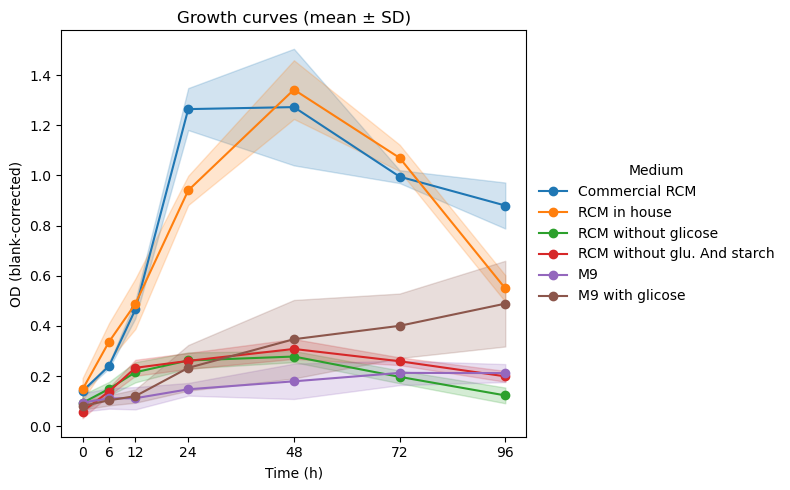

In [103]:
import matplotlib.pyplot as plt
from pathlib import Path


fig, ax = plt.subplots(figsize=(8, 5))

for medium, color in colors.items():
    d = summary[summary["medium"] == medium].sort_values("time_h")

    # Mean curve
    ax.plot(d["time_h"], d["mean"], marker="o", color=color, label=medium)

    # Shaded band: mean ± SD
    ax.fill_between(
        d["time_h"],
        d["mean"] - d["sd"],
        d["mean"] + d["sd"],
        color=color,
        alpha=0.2,
    )

ax.set_xticks(sorted(summary["time_h"].unique()))  # only the measured times
ax.set_xlabel("Time (h)")
ax.set_ylabel("OD (blank-corrected)")
ax.set_title("Growth curves (mean ± SD)")
ax.legend(title="Medium",
          frameon=False,
          loc="center left",
          bbox_to_anchor=(1, 0.5))  # legend outside the plot
output_dir = Path(output)   # your predefined folder
formats = ["png", "pdf", "svg"]   # add or remove formats here

for fmt in formats:
    fig.savefig(
        output_dir / f"growth_curves.{fmt}",
        dpi=300,                  # only affects png/tiff
        bbox_inches="tight",
    )
fig.tight_layout()
plt.show()

Normality test

In [104]:
# Shapiro-Wilk test for normality (medium vs time)
from scipy import stats

rows = []

for (t, m), d in cultures.groupby(["time_h", "medium"]):
    w, p = stats.shapiro(d["od_corrected"])
    rows.append({"time_h": t, "medium": m, "n": len(d), "W": w, "p": p})

normality = pd.DataFrame(rows)
normality["normal"] = normality["p"] > 0.05

normality[~normality["normal"]]   # show only the groups that fail

,time_h,medium,n,W,p,normal
1,0,M9,5,0.724973,0.017166,False
9,6,RCM in house,5,0.729462,0.018994,False
13,12,M9,5,0.709885,0.012117,False
24,48,Commercial RCM,5,0.725766,0.017477,False
39,96,RCM in house,5,0.710149,0.012192,False


In [105]:
# Homogeneity of variance test (Levene's test) for each time point
rows = []

for t, d in cultures.groupby("time_h"):
    groups = [g["od_corrected"].values for _, g in d.groupby("medium")]
    stat, p = stats.levene(*groups, center="median")   # median = robust version (Brown-Forsythe)
    rows.append({"time_h": t, "levene_p": p})

variance_check = pd.DataFrame(rows)
variance_check["equal_var"] = variance_check["levene_p"] > 0.05

variance_check

,time_h,levene_p,equal_var
0,0,0.239999,True
1,6,0.255192,True
2,12,0.635669,True
3,24,0.142235,True
4,48,0.337043,True
5,72,0.067469,True
6,96,0.229944,True


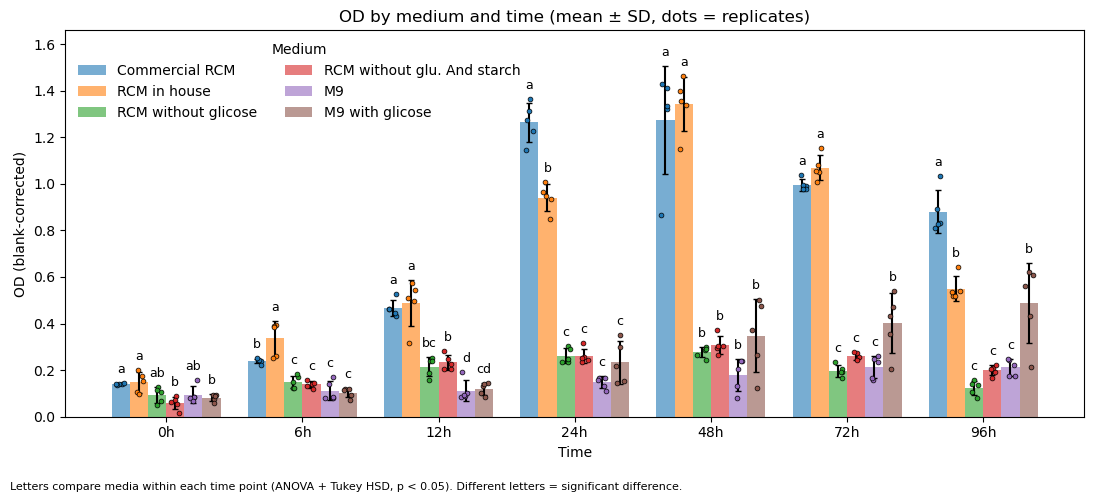

In [109]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

alpha = 0.05
media = list(colors)


def compact_letters(names, means, p_matrix, alpha=0.05):
    """Give the same letter to groups that are NOT significantly different."""
    order = sorted(range(len(names)), key=lambda k: -means[k])   # highest mean first
    cols = [set(range(len(names)))]                              # start: all groups share one letter

    for a, b in itertools.combinations(range(len(names)), 2):
        if p_matrix[a, b] < alpha:                               # a and b differ: they can't share a letter
            new = []
            for c in cols:
                if a in c and b in c:
                    new += [c - {a}, c - {b}]                    # split the column in two
                else:
                    new.append(c)
            # drop empty, duplicated and contained columns
            cols = [
                c for k, c in enumerate(new)
                if c and not any((c < d) or (c == d and k > j) for j, d in enumerate(new) if j != k)
            ]

    rank = {g: r for r, g in enumerate(order)}
    cols.sort(key=lambda c: min(rank[g] for g in c))             # letter 'a' -> highest-mean group

    letters = {g: "" for g in range(len(names))}
    for letter, c in zip("abcdefghij", cols):
        for g in c:
            letters[g] += letter
    return {names[g]: letters[g] for g in letters}


means = summary.pivot(index="time_h", columns="medium", values="mean")[media]
sds = summary.pivot(index="time_h", columns="medium", values="sd")[media]
times = means.index.tolist()

# ANOVA is implicit in Tukey HSD: one test per time point, all media vs all media
letters = {}
for t in times:
    d = cultures[cultures["time_h"] == t]
    groups = [d.loc[d["medium"] == m, "od_corrected"].values for m in media]
    tukey = stats.tukey_hsd(*groups)
    letters[t] = compact_letters(media, [g.mean() for g in groups], tukey.pvalue, alpha)

x = np.arange(len(times))
n = len(colors)
width = 0.8 / n
rng = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=(11, 5))

for i, (medium, color) in enumerate(colors.items()):
    offset = (i - (n - 1) / 2) * width

    ax.bar(
        x + offset, means[medium], width,
        yerr=sds[medium], capsize=2,
        color=color, alpha=0.6, label=medium,
    )

    for xi, t in zip(x, times):
        pts = cultures[(cultures["medium"] == medium) & (cultures["time_h"] == t)]["od_corrected"]
        jitter = rng.uniform(-width * 0.25, width * 0.25, size=len(pts))
        ax.scatter(
            xi + offset + jitter, pts,
            s=12, color=color, edgecolor="black", linewidth=0.5, zorder=3,
        )

        # Significance letter above the highest element (error bar or dot)
        top = max(means.loc[t, medium] + sds.loc[t, medium], pts.max())
        ax.text(xi + offset, top + 0.03, letters[t][medium],
                ha="center", va="bottom", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels([f"{t}h" for t in times])
ax.set_xlabel("Time")
ax.set_ylabel("OD (blank-corrected)")
ax.set_title("OD by medium and time (mean ± SD, dots = replicates)")
ax.legend(title="Medium", frameon=False, ncol=2, loc="upper left")
ax.set_ylim(0, ax.get_ylim()[1] * 1.05)    # room for the letters

fig.text(
    0.01, 0.01,
    "Letters compare media within each time point (ANOVA + Tukey HSD, p < 0.05). "
    "Different letters = significant difference.",
    fontsize=8,
)

fig.tight_layout(rect=(0, 0.04, 1, 1))     # leaves space for the footnote

# Save after the layout is final
output_dir = Path(output)
for fmt in ["png", "pdf", "svg"]:
    fig.savefig(output_dir / f"growth_bars.{fmt}", dpi=300, bbox_inches="tight")

plt.show()